In [1]:
import pandas as pd
from abi.forward.estate import *
import matplotlib.pyplot as plt
import json

In [2]:
lots = pd.read_csv('resources/lots.csv')

lots

,lot_id,area,rate
0,1,2727.0,824.749303
1,2,90.5,NaN
2,3,155.6,1728.333355
3,4,1.0,7045.500000
4,5,32.7,3895.444037
...,...,...,...
137,140,83.0,NaN
138,141,70.9,NaN
139,142,64.0,NaN
140,143,161.9,NaN


Если ставка у объекта отсутствует, то заполняем её медианной ставкой из объектов с похожей площадью

In [3]:
lots["rate_imputed"] = lots["rate"].isna()
lots["area_bin"] = pd.qcut(lots["area"], q=4, labels=False, duplicates="drop")
bin_median = lots.groupby("area_bin")["rate"].transform("median")
lots["rate_filled"] = lots["rate"].fillna(bin_median).fillna(lots["rate"].median())

In [4]:
lots["area_norm"] = lots["area"].rank(method="average") / (len(lots) + 1)

In [5]:
RATE_LO_NORM, RATE_HI_NORM = 0.1, 0.9
rate_lo = float(lots["rate_filled"].min())
rate_hi = float(lots["rate_filled"].max())
lots["rate_norm"] = RATE_LO_NORM + (RATE_HI_NORM - RATE_LO_NORM) * (
    (lots["rate_filled"] - rate_lo) / (rate_hi - rate_lo)
)

In [6]:
rng = np.random.default_rng(42)
location = rng.uniform(0.2, 0.8, size=len(lots))

rates = lots["rate_norm"].to_numpy(dtype=np.float32)
fixed_features = np.column_stack([lots["area_norm"], location]).astype(np.float32)

np.savez("resources/portfolio_real.npz",
         lot_id=lots["lot_id"].to_numpy(), rates=rates, fixed_features=fixed_features,
         area=lots["area"].to_numpy(dtype=np.float32), rate_imputed=lots["rate_imputed"].to_numpy())
with open("resources/normalization.json", "w") as f:
    json.dump({"rate_lo": rate_lo, "rate_hi": rate_hi,
               "rate_lo_norm": RATE_LO_NORM, "rate_hi_norm": RATE_HI_NORM,
               "area": "percentile_rank", "location": "synthetic_uniform_0.2_0.8_seed42"}, f, indent=2)


In [7]:
def denorm_rate(x):
    """Нормированная ставка -> руб./м² в месяц."""
    return rate_lo + (np.asarray(x) - RATE_LO_NORM) / (RATE_HI_NORM - RATE_LO_NORM) * (rate_hi - rate_lo)

In [8]:
print("Лотов:", len(lots), "| ставок заполнено:", int(lots["rate_imputed"].sum()))
print(lots[["area_norm", "rate_norm"]].describe().round(3))
print("Медианная ставка в нормированной шкале:", round(float(np.median(rates)), 3))
assert np.allclose(denorm_rate(rates), lots["rate_filled"], rtol=1e-4)

Лотов: 142 | ставок заполнено: 28
       area_norm  rate_norm
count    142.000    142.000
mean       0.500      0.320
std        0.288      0.088
min        0.007      0.100
25%        0.253      0.290
50%        0.500      0.299
75%        0.747      0.345
max        0.993      0.900
Медианная ставка в нормированной шкале: 0.299


In [9]:
lots

,lot_id,area,rate,rate_imputed,area_bin,rate_filled,area_norm,rate_norm
0,1,2727.0,824.749303,False,3,824.749303,0.993007,0.193648
1,2,90.5,NaN,True,2,1732.444488,0.517483,0.296715
2,3,155.6,1728.333355,False,3,1728.333355,0.874126,0.296248
3,4,1.0,7045.500000,False,0,7045.500000,0.006993,0.900000
4,5,32.7,3895.444037,False,0,3895.444037,0.069930,0.542319
...,...,...,...,...,...,...,...,...
137,140,83.0,NaN,True,1,1890.389898,0.426573,0.314649
138,141,70.9,NaN,True,1,1890.389898,0.349650,0.314649
139,142,64.0,NaN,True,1,1890.389898,0.286713,0.314649
140,143,161.9,NaN,True,3,1749.081152,0.895105,0.298604


Прямой прогон симулятора на реальных данных

In [10]:
from abi.forward.estate import RealEstateSimulator
from abi.inverse.builders import build_competitors, DEFAULT_COMPETITOR_SIZES
from abi.inverse.scenario import MarketScenario
from abi.inverse.builders import build_agents

In [11]:
data = np.load("resources/portfolio_real.npz")
rates = data["rates"]                    # (N_PROPS,) нормированные ставки
fixed_features = data["fixed_features"]  # (N_PROPS, 2): area_norm, location
area_real = data["area"]                 # реальные площади, м² (для заполняемости как в данных)
N_PROPS = len(rates)

In [12]:
T = 200
K = 20
N_AGENTS = 300
SEED = 0
REF_CENTER, REF_STD = 0.5, 0.1
SWITCHING_COST_SCALE = 0.3
UTILITY_SCALE = 3.0
OUTSIDE_UTILITY = 1.0
OUTSIDE_SIZE = 1.0          # DEFAULT_OUTSIDE_SIZE из демо
WEIGHTS = np.array([0.4, 0.3, 0.3], dtype=np.float32)       # rate, area, location
DIRECTIONS = np.array([-1.0, 1.0, 1.0], dtype=np.float32)

In [13]:
rng = np.random.default_rng(SEED)
refs = np.clip(rng.normal(REF_CENTER, REF_STD, size=(N_AGENTS, 3)), 0.0, 1.0).astype(np.float32)
switching_costs = np.clip(rng.normal(0.2, 0.05, size=N_AGENTS) * SWITCHING_COST_SCALE,
                          1e-6, None).astype(np.float32)
current_choice = np.full(N_AGENTS, -1, dtype=np.int32)
visible = rng.random((N_AGENTS, N_PROPS)).argsort(axis=1)[:, :K].astype(np.int32)

In [14]:
competitors = build_competitors()
assert competitors.shape[1] == 3, f"ожидались 3 признака у конкурентов, получено {competitors.shape}"

sim = RealEstateSimulator(
    T=T, K=K,
    outside_utility=OUTSIDE_UTILITY,
    outside_size=OUTSIDE_SIZE,
    competitor_sizes=np.asarray(DEFAULT_COMPETITOR_SIZES, dtype=np.float32) * 5,
    utility_scale=UTILITY_SCALE,
)

scenario = MarketScenario(n_agents=N_AGENTS, ref_center=0.5, ref_std=0.1,
                          switching_cost_scale=SWITCHING_COST_SCALE)
agents = build_agents(scenario, WEIGHTS, DIRECTIONS, n_props=N_PROPS, K=K, seed=SEED)
gumbel = sim.sample_gumbel(N_AGENTS, seed=SEED)
res = sim.run(
    rates=rates,
    fixed_features=fixed_features,
    competitor_features=competitors,
    agents_ref=agents["refs"],
    agents_w=agents["w"],
    agents_directions=agents["directions"],
    agents_switching_cost=agents["switching_costs"],
    agents_current_choice=agents["current_choice"],
    agents_to_properties=agents["agent_to_properties"],
    gumbel=gumbel,
)

In [15]:
occ_hist = res["occupied_history"]                    # (T, N_PROPS) bool
area_norm = fixed_features[:, 0]
occ_check = (occ_hist * area_norm).sum(axis=1) / area_norm.sum()
assert np.allclose(occ_check, res["portfolio_share_history"], atol=1e-5), "матрица не совпадает с ядром"
print("Проверка матрицы: OK")

Проверка матрицы: OK


In [16]:
occ_real = (occ_hist * area_real).sum(axis=1) / area_real.sum()
occ_count = occ_hist.mean(axis=1)

print(f"Равновесие (последние 20 шагов): по реальной площади {occ_real[-20:].mean():.3f}, "
      f"по штукам {occ_count[-20:].mean():.3f}, по нормированной площади {res['occupancy']:.3f}")

Равновесие (последние 20 шагов): по реальной площади 0.771, по штукам 0.637, по нормированной площади 0.744


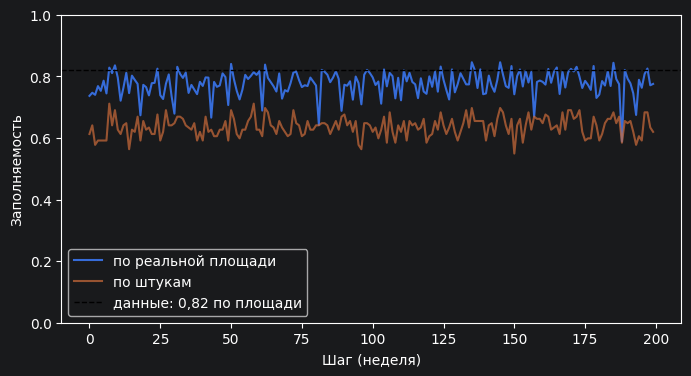

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(occ_real, label="по реальной площади")
ax.plot(occ_count, label="по штукам", alpha=0.7)
ax.axhline(0.82, color="black", linestyle="--", linewidth=1, label="данные: 0,82 по площади")
ax.set_xlabel("Шаг (неделя)")
ax.set_ylabel("Заполняемость")
ax.set_ylim(0, 1)
ax.legend()
plt.show()